# ***Credit Risk Analysis and Loan Default Prediction***
---

This project aims to enhance my knowledge of core data science concepts such as data preprocessing, exploratory data analysis, and model fitting. I will conduct a credit risk analysis and build a loan default prediction system using parameters derived from a real-world dataset.

### Introduction
Default occurs when scheduled payments of interest or principal on a debt are not made according to the agreed terms, whether that debt is a loan or a security. Individuals, businesses, and even countries can default on their debt obligations. Default risk is an important consideration for creditors.

Once a loan is defaulted, there are severe consequences such as credit score damage, asset seizure, difficulty opening bank accounts, acquiring loans from other banks, and potential tax consequences.

Certain parameters are set in place to ensure loan default is detected early. The primary early detection point of loan default is loan delinquency. Loan delinquency occurs when a borrower fails to make a scheduled loan payment by its due date, even by a single day, making the account past due.

### Project Description
This project analyzes a real-world credit dataset to build a loan default detection system. The analysis establishes data-driven parameters defining what constitutes loan default and loan delinquency, which then informs the design of two predictive classification models: Logistic Regression and a Linear Support Vector Machine (SVM).

The full pipeline follows the sequence: data cleaning -> parameter definition -> encoding -> scaling -> model training -> evaluation.

# **About the Dataset**

Source: Kaggle

URL: https://www.kaggle.com/datasets/zaurbegiev/my-dataset

### Project Steps

**1. Preprocessing Tasks**
* Handling missing or inconsistent data
* Removing extreme outliers
* One-hot encoding categorical variables to convert them into a numerical format
* Splitting the dataset into feature (X) and target (y) variables

**2. Model Selection, Fitting, Evaluation, and Testing**
* Building a Pipeline for Logistic Regression and Linear SVM.
* The pipeline includes: imputation, encoding, scaling, and algorithm training.
* Evaluate the performance of both models against the test set.
* Provide insights into the effectiveness of the two models and determine which is best suited for the system.

**3. Conclusion**
* Summarize key findings from the exploratory analysis and model testing.

In [1]:
!pip install --upgrade scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 81.6 MB/s eta 0:00:00
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.6.1
    Uninstalling scikit-learn-1.6.1:
      Successfully uninstalled scikit-learn-1.6.1


In [2]:
#libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.metrics import (classification_report, confusion_matrix,
                           roc_auc_score, roc_curve, accuracy_score,
                           precision_recall_curve, average_precision_score)
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
import math
import warnings
warnings.filterwarnings('ignore')

In [3]:
#read data
print("=== DATASET OVERVIEW ===")

import kagglehub
from kagglehub import KaggleDatasetAdapter

file_path = "credit_train.csv"

# Load the latest version
loan_ds = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "zaurbegiev/my-dataset",
  file_path,
)
print(loan_ds.info())
loan_ds.head()

=== DATASET OVERVIEW ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100514 entries, 0 to 100513
Data columns (total 19 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   Loan ID                       100000 non-null  object 
 1   Customer ID                   100000 non-null  object 
 2   Loan Status                   100000 non-null  object 
 3   Current Loan Amount           100000 non-null  float64
 4   Term                          100000 non-null  object 
 5   Credit Score                  80846 non-null   float64
 6   Annual Income                 80846 non-null   float64
 7   Years in current job          95778 non-null   object 
 8   Home Ownership                100000 non-null  object 
 9   Purpose                       100000 non-null  object 
 10  Monthly Debt                  100000 non-null  float64
 11  Years of Credit History       100000 non-null  float64
 12  Months since last d

,Loan ID,Customer ID,Loan Status,Current Loan Amount,Term,Credit Score,Annual Income,Years in current job,Home Ownership,Purpose,Monthly Debt,Years of Credit History,Months since last delinquent,Number of Open Accounts,Number of Credit Problems,Current Credit Balance,Maximum Open Credit,Bankruptcies,Tax Liens
0,14dd8831-6af5-400b-83ec-68e61888a048,981165ec-3274-42f5-a3b4-d104041a9ca9,Fully Paid,445412.0,Short Term,709.0,1167493.0,8 years,Home Mortgage,Home Improvements,5214.74,17.2,NaN,6.0,1.0,228190.0,416746.0,1.0,0.0
1,4771cc26-131a-45db-b5aa-537ea4ba5342,2de017a3-2e01-49cb-a581-08169e83be29,Fully Paid,262328.0,Short Term,NaN,NaN,10+ years,Home Mortgage,Debt Consolidation,33295.98,21.1,8.0,35.0,0.0,229976.0,850784.0,0.0,0.0
2,4eed4e6a-aa2f-4c91-8651-ce984ee8fb26,5efb2b2b-bf11-4dfd-a572-3761a2694725,Fully Paid,99999999.0,Short Term,741.0,2231892.0,8 years,Own Home,Debt Consolidation,29200.53,14.9,29.0,18.0,1.0,297996.0,750090.0,0.0,0.0
3,77598f7b-32e7-4e3b-a6e5-06ba0d98fe8a,e777faab-98ae-45af-9a86-7ce5b33b1011,Fully Paid,347666.0,Long Term,721.0,806949.0,3 years,Own Home,Debt Consolidation,8741.90,12.0,NaN,9.0,0.0,256329.0,386958.0,0.0,0.0
4,d4062e70-befa-4995-8643-a0de73938182,81536ad9-5ccf-4eb8-befb-47a4d608658e,Fully Paid,176220.0,Short Term,NaN,NaN,5 years,Rent,Debt Consolidation,20639.70,6.1,NaN,15.0,0.0,253460.0,427174.0,0.0,0.0


We now assess how many columns have null rows. this will help us determine the steps that need to be taken during data cleaning


In [4]:
#checking for null values
null_values = loan_ds.isnull().sum()
print("Null values in each column:")
print(null_values)

Null values in each column:
Loan ID                           514
Customer ID                       514
Loan Status                       514
Current Loan Amount               514
Term                              514
Credit Score                    19668
Annual Income                   19668
Years in current job             4736
Home Ownership                    514
Purpose                           514
Monthly Debt                      514
Years of Credit History           514
Months since last delinquent    53655
Number of Open Accounts           514
Number of Credit Problems         514
Current Credit Balance            514
Maximum Open Credit               516
Bankruptcies                      718
Tax Liens                         524
dtype: int64


**Data Cleaning**

In this part of the project we go through the datset and clean it. This involves formatting, removing nulls, outliers etc.

This will make it easier to go about preprocessing the dataset for model fitting

Firstly, we format the Years in current job row to integers only.

All rows with "10+ years" will now be "10" and all rows with "< 1 year" will be "1"

In [5]:
loan_ds["Years in current job"] = (
    loan_ds["Years in current job"]
    .astype(str)  # Convert to string to ensure .str accessor works
    .str.extract(r"(\d+)", expand=False) # extract digits, expand=False returns a Series
    .astype(float)
)
loan_ds[["Years in current job"]].head(10)


,Years in current job
0,8.0
1,10.0
2,8.0
3,3.0
4,5.0
5,10.0
6,1.0
7,1.0
8,2.0
9,1.0


In [6]:
loan_ds.head()

,Loan ID,Customer ID,Loan Status,Current Loan Amount,Term,Credit Score,Annual Income,Years in current job,Home Ownership,Purpose,Monthly Debt,Years of Credit History,Months since last delinquent,Number of Open Accounts,Number of Credit Problems,Current Credit Balance,Maximum Open Credit,Bankruptcies,Tax Liens
0,14dd8831-6af5-400b-83ec-68e61888a048,981165ec-3274-42f5-a3b4-d104041a9ca9,Fully Paid,445412.0,Short Term,709.0,1167493.0,8.0,Home Mortgage,Home Improvements,5214.74,17.2,NaN,6.0,1.0,228190.0,416746.0,1.0,0.0
1,4771cc26-131a-45db-b5aa-537ea4ba5342,2de017a3-2e01-49cb-a581-08169e83be29,Fully Paid,262328.0,Short Term,NaN,NaN,10.0,Home Mortgage,Debt Consolidation,33295.98,21.1,8.0,35.0,0.0,229976.0,850784.0,0.0,0.0
2,4eed4e6a-aa2f-4c91-8651-ce984ee8fb26,5efb2b2b-bf11-4dfd-a572-3761a2694725,Fully Paid,99999999.0,Short Term,741.0,2231892.0,8.0,Own Home,Debt Consolidation,29200.53,14.9,29.0,18.0,1.0,297996.0,750090.0,0.0,0.0
3,77598f7b-32e7-4e3b-a6e5-06ba0d98fe8a,e777faab-98ae-45af-9a86-7ce5b33b1011,Fully Paid,347666.0,Long Term,721.0,806949.0,3.0,Own Home,Debt Consolidation,8741.90,12.0,NaN,9.0,0.0,256329.0,386958.0,0.0,0.0
4,d4062e70-befa-4995-8643-a0de73938182,81536ad9-5ccf-4eb8-befb-47a4d608658e,Fully Paid,176220.0,Short Term,NaN,NaN,5.0,Rent,Debt Consolidation,20639.70,6.1,NaN,15.0,0.0,253460.0,427174.0,0.0,0.0


In [7]:
loan_ds.shape

(100514, 19)

Loan ID and Customer ID have the same ammount of null values, so they will be dropped.

In [8]:
loan_ds = loan_ds.dropna(subset=["Loan ID", "Customer ID"])

In [9]:
loan_ds.shape

(100000, 19)

In [10]:
#checking for null values
null_values = loan_ds.isnull().sum()
print("Null values in each column:")
print(null_values)

Null values in each column:
Loan ID                             0
Customer ID                         0
Loan Status                         0
Current Loan Amount                 0
Term                                0
Credit Score                    19154
Annual Income                   19154
Years in current job             4222
Home Ownership                      0
Purpose                             0
Monthly Debt                        0
Years of Credit History             0
Months since last delinquent    53141
Number of Open Accounts             0
Number of Credit Problems           0
Current Credit Balance              0
Maximum Open Credit                 2
Bankruptcies                      204
Tax Liens                          10
dtype: int64


In [11]:
loan_ds.describe()

,Current Loan Amount,Credit Score,Annual Income,Years in current job,Monthly Debt,Years of Credit History,Months since last delinquent,Number of Open Accounts,Number of Credit Problems,Current Credit Balance,Maximum Open Credit,Bankruptcies,Tax Liens
count,1.000000e+05,80846.000000,8.084600e+04,95778.000000,100000.000000,100000.000000,46859.000000,100000.00000,100000.000000,1.000000e+05,9.999800e+04,99796.000000,99990.000000
mean,1.176045e+07,1076.456089,1.378277e+06,5.977594,18472.412336,18.199141,34.901321,11.12853,0.168310,2.946374e+05,7.607984e+05,0.117740,0.029313
std,3.178394e+07,1475.403791,1.081360e+06,3.501109,12174.992609,7.015324,21.997829,5.00987,0.482705,3.761709e+05,8.384503e+06,0.351424,0.258182
min,1.080200e+04,585.000000,7.662700e+04,1.000000,0.000000,3.600000,0.000000,0.00000,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000
25%,1.796520e+05,705.000000,8.488440e+05,3.000000,10214.162500,13.500000,16.000000,8.00000,0.000000,1.126700e+05,2.734380e+05,0.000000,0.000000
50%,3.122460e+05,724.000000,1.174162e+06,6.000000,16220.300000,16.900000,32.000000,10.00000,0.000000,2.098170e+05,4.678740e+05,0.000000,0.000000
75%,5.249420e+05,741.000000,1.650663e+06,10.000000,24012.057500,21.700000,51.000000,14.00000,0.000000,3.679588e+05,7.829580e+05,0.000000,0.000000
max,1.000000e+08,7510.000000,1.655574e+08,10.000000,435843.280000,70.500000,176.000000,76.00000,15.000000,3.287897e+07,1.539738e+09,7.000000,15.000000


In [12]:
missing_AI_CS = loan_ds[
    loan_ds['Annual Income'].isna() |
    loan_ds['Credit Score'].isna()
]


In [13]:
loan_ds[['Annual Income', 'Credit Score']].isna().sum()

,0
Annual Income,19154
Credit Score,19154


It is noticed that NaN rows in Credit Score are the same rows as the NaN rows in Annunal income, so we run the missing colums only to see if they coincide with any other NaN rows from the other columns.

In [14]:
missing_AI_CS

,Loan ID,Customer ID,Loan Status,Current Loan Amount,Term,Credit Score,Annual Income,Years in current job,Home Ownership,Purpose,Monthly Debt,Years of Credit History,Months since last delinquent,Number of Open Accounts,Number of Credit Problems,Current Credit Balance,Maximum Open Credit,Bankruptcies,Tax Liens
1,4771cc26-131a-45db-b5aa-537ea4ba5342,2de017a3-2e01-49cb-a581-08169e83be29,Fully Paid,262328.0,Short Term,NaN,NaN,10.0,Home Mortgage,Debt Consolidation,33295.98,21.1,8.0,35.0,0.0,229976.0,850784.0,0.0,0.0
4,d4062e70-befa-4995-8643-a0de73938182,81536ad9-5ccf-4eb8-befb-47a4d608658e,Fully Paid,176220.0,Short Term,NaN,NaN,5.0,Rent,Debt Consolidation,20639.70,6.1,NaN,15.0,0.0,253460.0,427174.0,0.0,0.0
7,db0dc6e1-77ee-4826-acca-772f9039e1c7,018973c9-e316-4956-b363-67e134fb0931,Charged Off,648714.0,Long Term,NaN,NaN,1.0,Home Mortgage,Buy House,14806.13,8.2,8.0,15.0,0.0,193306.0,864204.0,0.0,0.0
11,fa096848-6143-4907-b2cf-852a0b06171c,aa0a6a22-a95e-48e0-ba4f-b83456d424e4,Fully Paid,541970.0,Short Term,NaN,NaN,10.0,Home Mortgage,Home Improvements,23568.55,23.2,NaN,23.0,0.0,60705.0,1634468.0,0.0,0.0
15,7cbaa3fa-16fd-4343-9bcb-e90b34a1072f,3ec886e7-f15d-4c35-83d0-bdec4817ae4b,Fully Paid,449020.0,Long Term,NaN,NaN,9.0,Own Home,Debt Consolidation,18904.81,19.4,NaN,8.0,0.0,334533.0,428956.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99978,94eaa3d9-2b9f-467b-855f-9e8f5eae57a4,4dba3a9b-1a39-4464-88df-c7f8735944d1,Fully Paid,431860.0,Long Term,NaN,NaN,10.0,Home Mortgage,Debt Consolidation,8465.07,18.5,25.0,5.0,0.0,241319.0,476806.0,0.0,0.0
99982,81389d2c-963c-40d4-a8eb-8329a3efadad,b1cb4f71-83a5-4152-b11e-fdf071fa2eba,Fully Paid,484968.0,Long Term,NaN,NaN,10.0,Home Mortgage,Debt Consolidation,20941.80,23.7,NaN,15.0,0.0,804175.0,1322662.0,0.0,0.0
99988,125a4df1-c538-4b1e-b37f-b515a2ce370c,82488d29-ef29-4f1c-a786-dee1b257dee5,Charged Off,309474.0,Short Term,NaN,NaN,10.0,Home Mortgage,Debt Consolidation,13817.18,26.9,NaN,15.0,0.0,225872.0,892606.0,0.0,0.0
99989,2649e526-3866-4555-91a3-9bd5d26dcba2,9ff0267b-fa13-4f8e-b625-e8c36b6685e0,Charged Off,429132.0,Short Term,NaN,NaN,10.0,Home Mortgage,Debt Consolidation,28948.02,16.3,NaN,16.0,0.0,485279.0,656414.0,0.0,0.0


<Axes: xlabel='Loan Status'>

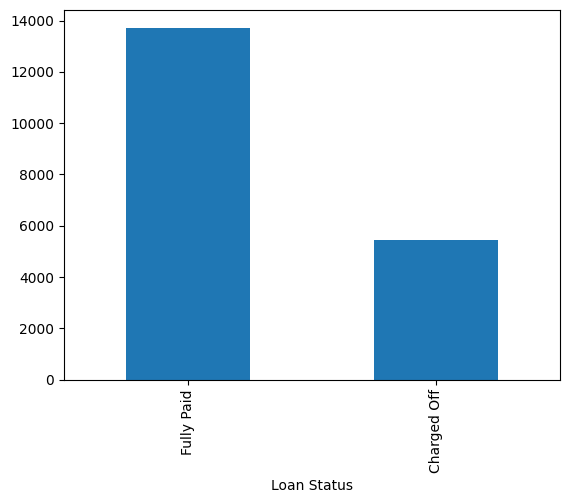

In [15]:
missing_AI_CS['Loan Status'].value_counts().plot(kind='bar')

In [16]:
cat_cols = missing_AI_CS.select_dtypes(include='object').columns.difference(['Loan ID', 'Customer ID'])
print("Categorical columns identified:")
print(cat_cols)

Categorical columns identified:
Index(['Home Ownership', 'Loan Status', 'Purpose', 'Term'], dtype='object')


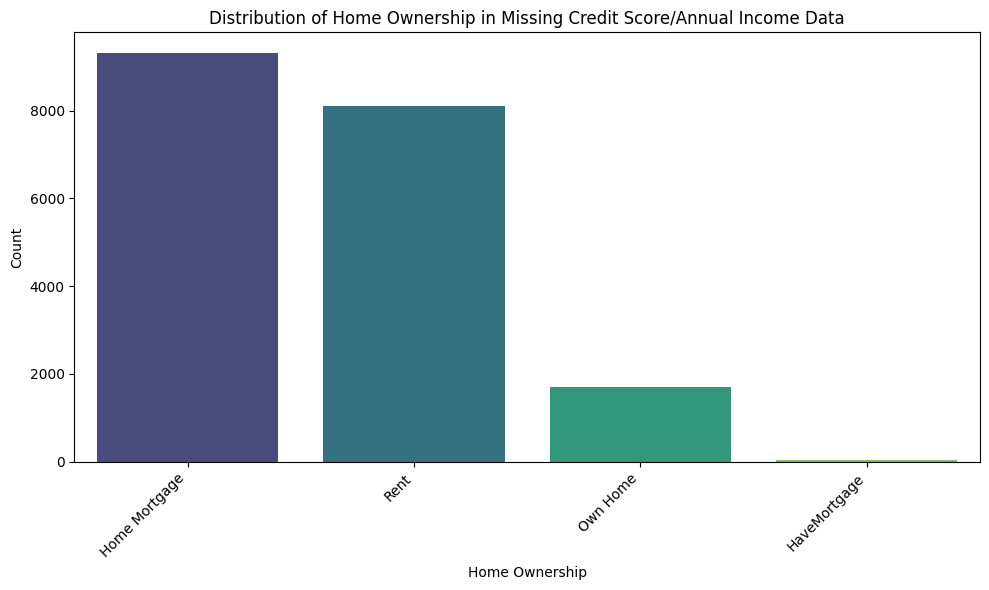

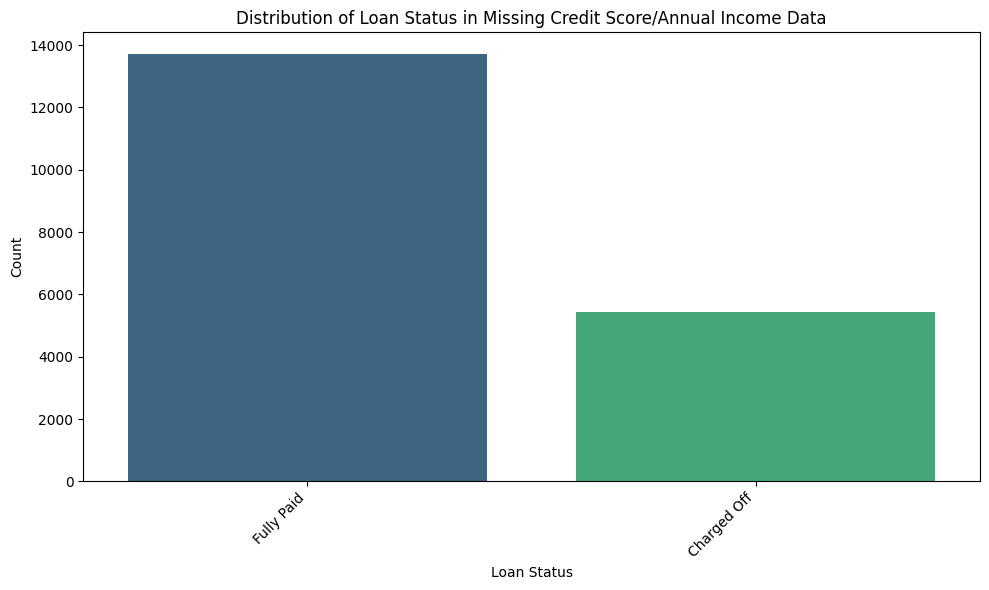

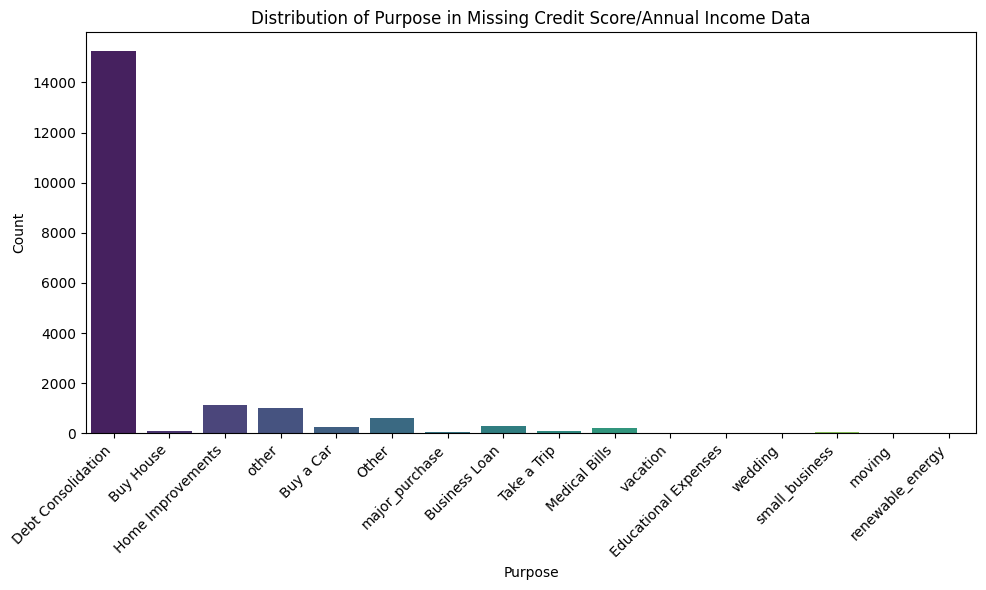

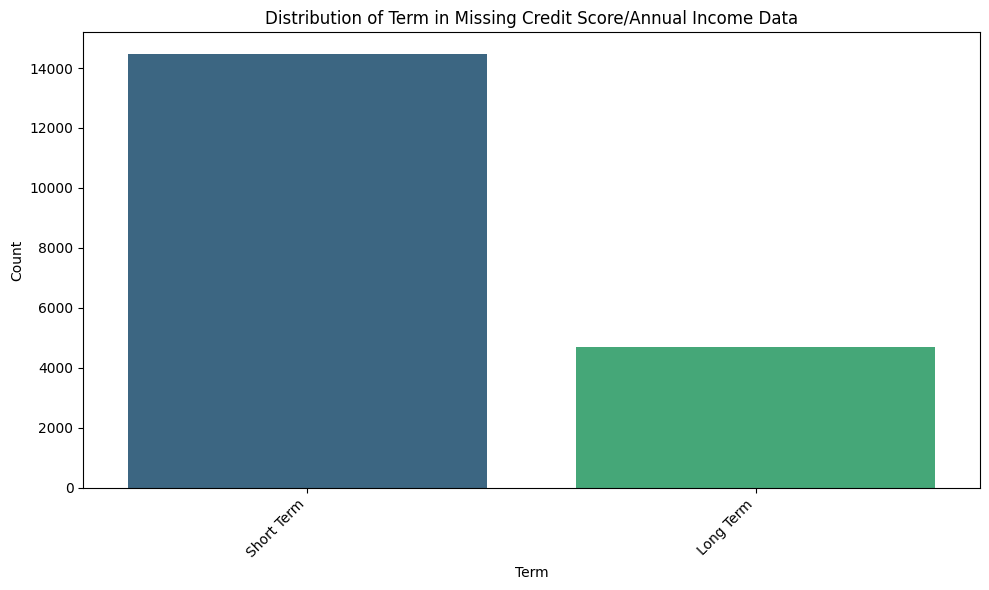

In [17]:
for col in cat_cols:
    plt.figure(figsize=(10, 6))
    sns.countplot(data=missing_AI_CS, x=col, palette='viridis')
    plt.title(f'Distribution of {col} in Missing Credit Score/Annual Income Data')
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

We now create scatterplots to determine outliers and get rid of extreme outliers and bring the data to a common average

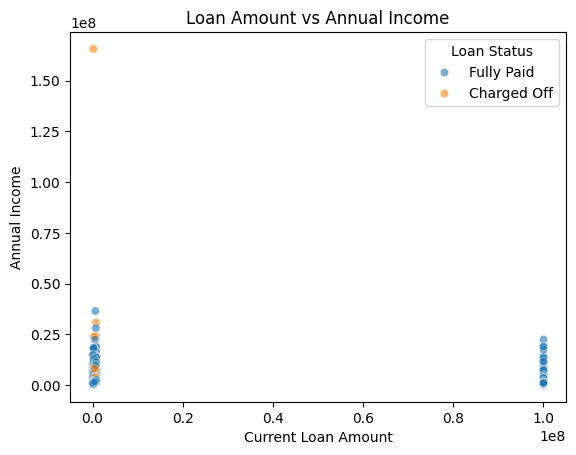

In [18]:
sns.scatterplot(
    data=loan_ds,
    x="Current Loan Amount",
    y="Annual Income",
    hue="Loan Status",
    alpha=0.6
)
plt.title("Loan Amount vs Annual Income")
plt.show()

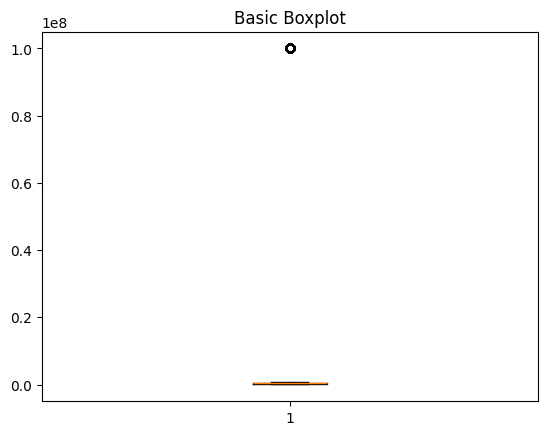

In [19]:
# Creates a boxplot
plt.boxplot(loan_ds['Current Loan Amount'])
plt.title('Basic Boxplot')
plt.show()

In [20]:
loan_ds['Current Loan Amount'].sort_values(ascending=False)

,Current Loan Amount
99971,99999999.0
13663,99999999.0
13649,99999999.0
62885,99999999.0
62874,99999999.0
...,...
79712,21098.0
79169,15422.0
19847,15422.0
13338,11242.0


seeing the excess 99999999 in Current Loan Amount and comparing that to the Annunal Income and Loan purpose, it is noted that the loan amount could be counted as an anomaly when compared to direct counterparts hence it shall be removed this will stabilize the column and remove drastic outliers

In [21]:
loan_ds = loan_ds[loan_ds['Current Loan Amount'] != 99999999]

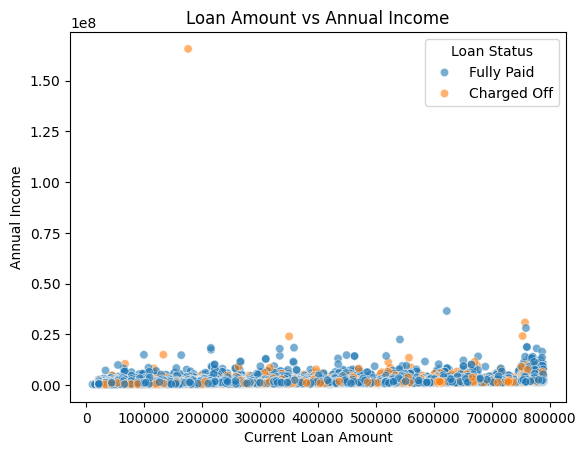

In [22]:
sns.scatterplot(
    data=loan_ds,
    x="Current Loan Amount",
    y="Annual Income",
    hue="Loan Status",
    alpha=0.6
)
plt.title("Loan Amount vs Annual Income")
plt.show()

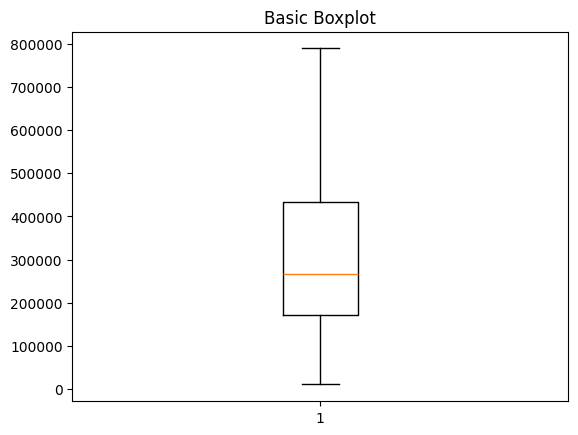

In [23]:
# Creates a boxplot
plt.boxplot(loan_ds['Current Loan Amount'])
plt.title('Basic Boxplot')
plt.show()

In [24]:
loan_ds['Current Loan Amount'].sort_values(ascending=False)

,Current Loan Amount
21017,789250.0
42195,789250.0
82002,789250.0
59266,789184.0
47636,789184.0
...,...
79712,21098.0
79169,15422.0
19847,15422.0
13338,11242.0


In [25]:
loan_ds['Current Loan Amount'].describe()

,Current Loan Amount
count,88516.000000
mean,312313.597881
std,186262.167690
min,10802.000000
25%,172342.500000
50%,267344.000000
75%,432663.000000
max,789250.000000


In [26]:
loan_ds['Annual Income'].describe()

,Annual Income
count,6.936200e+04
mean,1.373246e+06
std,1.103906e+06
min,7.662700e+04
25%,8.462790e+05
50%,1.167759e+06
75%,1.644564e+06
max,1.655574e+08


In [27]:
loan_ds['Annual Income'].sort_values(ascending=False)

,Annual Income
85662,165557393.0
37858,36475440.0
10721,30838995.0
58682,28095300.0
21598,24161540.0
...,...
99978,NaN
99982,NaN
99988,NaN
99989,NaN


seeing the excess large values and excess NaN values in Annual Income. This puts the average values at a lower percentile. Hence it shall be removed starting with 50000000 this will stabilize the column and remove drastic outliers

In [28]:
loan_ds = loan_ds[loan_ds['Annual Income'] <= 50000000]

In [29]:
loan_ds['Annual Income'].sort_values(ascending=False)

,Annual Income
37858,36475440.0
10721,30838995.0
58682,28095300.0
21598,24161540.0
25003,23980375.0
...,...
99256,111245.0
9610,111245.0
13090,97033.0
50646,81092.0


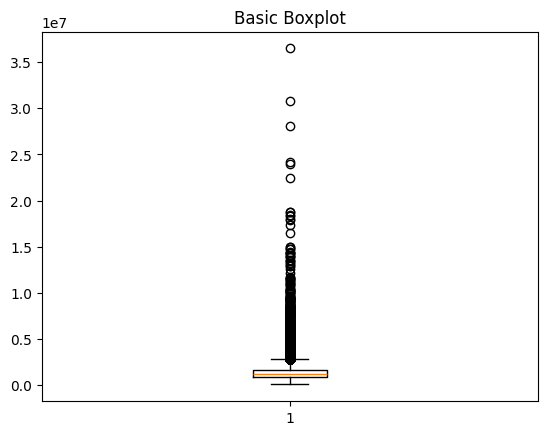

In [30]:
# Creates a boxplot
plt.boxplot(loan_ds['Annual Income'])
plt.title('Basic Boxplot')
plt.show()

We now plot graphs for all the columns to see any drastic outliers

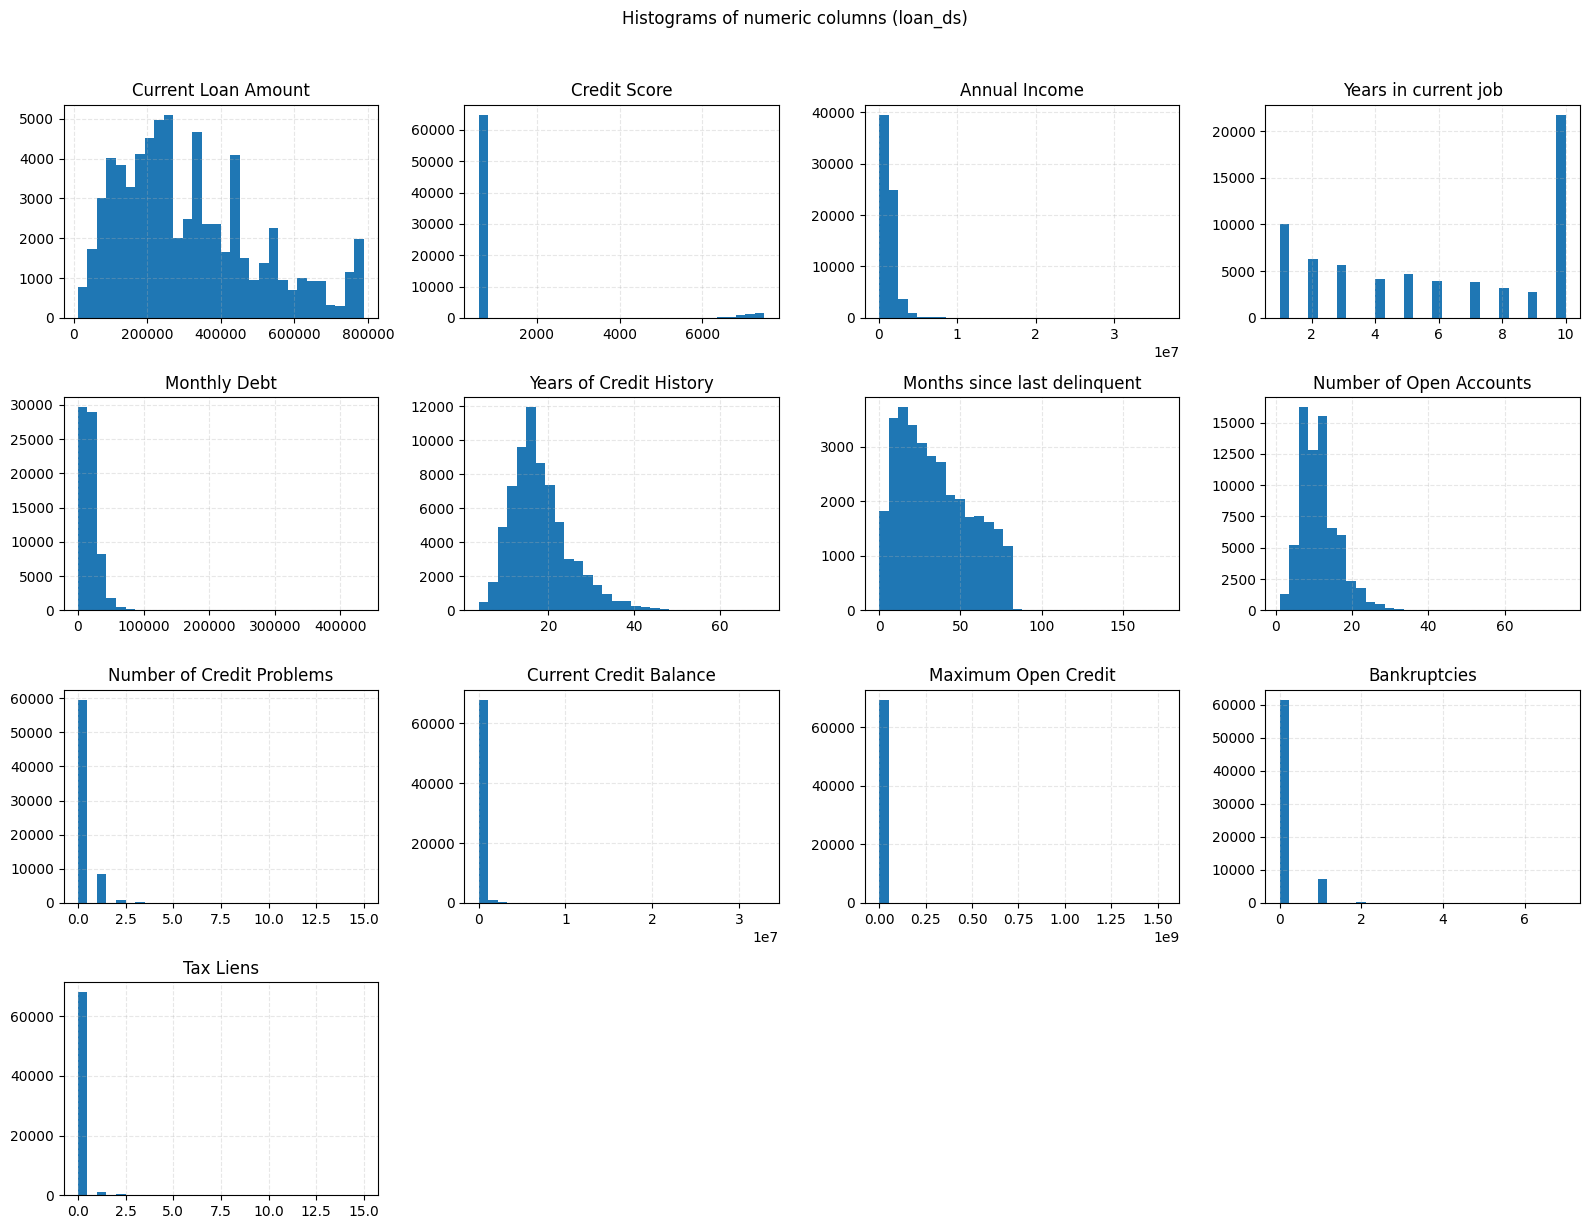

In [31]:
#numeric columns
num = loan_ds.select_dtypes(include="number")
cols = num.columns.tolist()

#grid
n = len(cols)
ncols = 4
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(4*ncols, 3*nrows))
axes = axes.ravel()

for i, c in enumerate(cols):
    ax = axes[i]
    ax.hist(num[c].dropna().values, bins=30)
    ax.set_title(c)
    ax.grid(True, linestyle="--", alpha=0.3)
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

fig.suptitle("Histograms of numeric columns (loan_ds)", y=1.02)
plt.tight_layout()
plt.show()


In [32]:
loan_ds['Credit Score'].sort_values(ascending=False)

,Credit Score
64774,7510.0
43351,7510.0
3748,7510.0
76476,7510.0
23322,7510.0
...,...
33328,585.0
74218,585.0
47547,585.0
45829,585.0


looking at the graphs, it is observed that credit score has an outlier that lies after about 2000, so we get rid of all values after 1500 to normalize the column and create graphs again to see how the graphs look afterwards

In [33]:
loan_ds = loan_ds[loan_ds['Credit Score'] <= 1500]

In [34]:
loan_ds['Credit Score'].sort_values(ascending=False)

,Credit Score
101,751.0
99883,751.0
90514,751.0
18990,751.0
5325,751.0
...,...
64829,585.0
25759,585.0
20074,585.0
28979,585.0


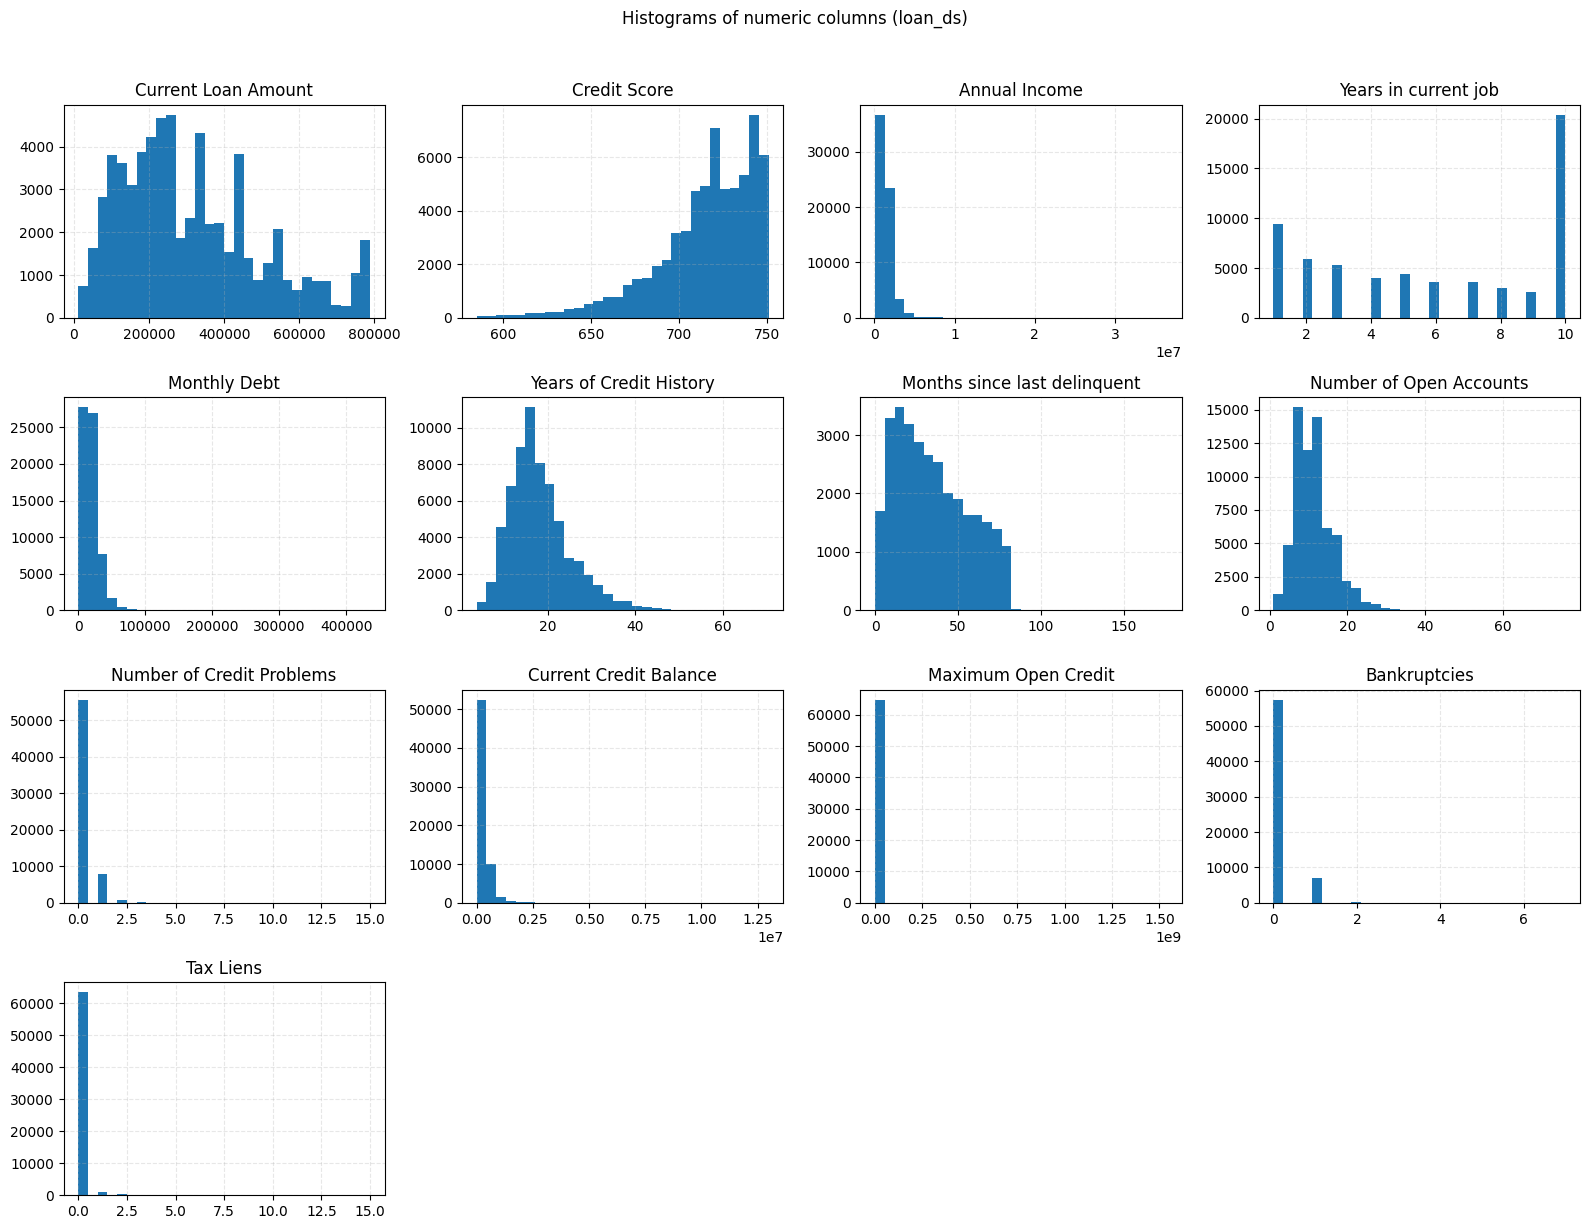

In [35]:
#numeric columns
num = loan_ds.select_dtypes(include="number")
cols = num.columns.tolist()

#grid
n = len(cols)
ncols = 4
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(4*ncols, 3*nrows))
axes = axes.ravel()

for i, c in enumerate(cols):
    ax = axes[i]
    ax.hist(num[c].dropna().values, bins=30)
    ax.set_title(c)
    ax.grid(True, linestyle="--", alpha=0.3)
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

fig.suptitle("Histograms of numeric columns (loan_ds)", y=1.02)
plt.tight_layout()
plt.show()


we now look at the remaining null values

In [36]:
loan_ds.isna().sum()

,0
Loan ID,0
Customer ID,0
Loan Status,0
Current Loan Amount,0
Term,0
Credit Score,0
Annual Income,0
Years in current job,2738
Home Ownership,0
Purpose,0


ADDED 20 AUG 2026

**Defining default and deliquency parameters**

This section will be used to state the parameters that define what loan deliquency is as well as define what loan default is.This will help ensure the model has the right parameters when data is fed into it

In [37]:
#Loan Default part

print("=== LOAN DEFAULT ANALYSIS ===\n")

status_counts = loan_ds['Loan Status'].value_counts()
status_pct    = loan_ds['Loan Status'].value_counts(normalize=True) * 100

print("Loan Status Distribution:")
for status in status_counts.index:
    print(f"  {status}: {status_counts[status]:,} loans ({status_pct[status]:.1f}%)")

=== LOAN DEFAULT ANALYSIS ===

Loan Status Distribution:
  Fully Paid: 52,152 loans (80.5%)
  Charged Off: 12,659 loans (19.5%)


In [38]:
print("=== DEFAULT PARAMETER ===")
print("""
DEFINITION: A loan is considered in DEFAULT when:
  - Loan Status = 'Charged Off'
  - This means the loan has not been paid, and the bank has determined that the borrower will not pay back their loan.
""".format(
    status_pct.get('Charged Off', 0),
    status_counts.get('Charged Off', 0)
))

=== DEFAULT PARAMETER ===

DEFINITION: A loan is considered in DEFAULT when:
  - Loan Status = 'Charged Off'
  - This means the loan has not been paid, and the bank has determined that the borrower will not pay back their loan.



In [39]:
# Deliquency part
print("=== LOAN DELINQUENCY ANALYSIS ===\n")

# Look at delinquency months distribution among Charged Off loans
charged_off = loan_ds[loan_ds['Loan Status'] == 'Charged Off']
fully_paid  = loan_ds[loan_ds['Loan Status'] == 'Fully Paid']

print("Months since last delinquent — Charged Off loans:")
print(charged_off['Months since last delinquent'].describe().round(2))

print("\nMonths since last delinquent — Fully Paid loans:")
print(fully_paid['Months since last delinquent'].describe().round(2))

=== LOAN DELINQUENCY ANALYSIS ===

Months since last delinquent — Charged Off loans:
count    5850.00
mean       34.19
std        22.06
min         0.00
25%        15.00
50%        31.00
75%        51.00
max        96.00
Name: Months since last delinquent, dtype: float64

Months since last delinquent — Fully Paid loans:
count    25112.00
mean        34.92
std         21.88
min          0.00
25%         16.00
50%         32.00
75%         51.00
max        176.00
Name: Months since last delinquent, dtype: float64


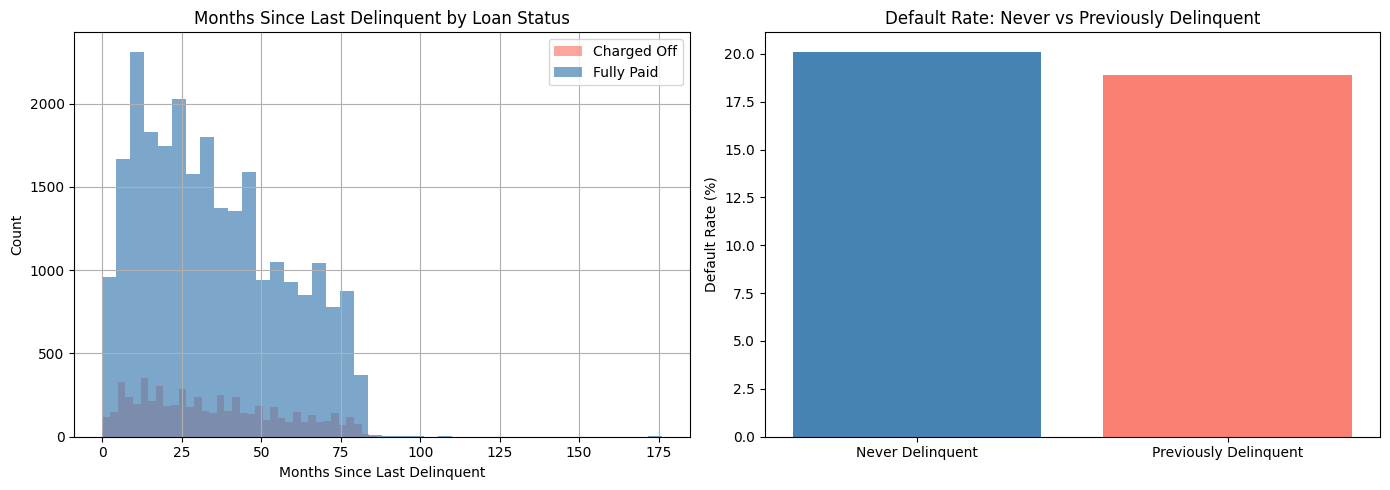

     Never Delinquent  Default Rate (%)
     Never Delinquent         20.115808
Previously Delinquent         18.894128


In [40]:
# Visualise delinquency patterns
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribution of months since delinquent by loan status
charged_off['Months since last delinquent'].dropna().hist(
    bins=40, ax=axes[0], color='salmon', alpha=0.7, label='Charged Off'
)
fully_paid['Months since last delinquent'].dropna().hist(
    bins=40, ax=axes[0], color='steelblue', alpha=0.7, label='Fully Paid'
)
axes[0].set_title('Months Since Last Delinquent by Loan Status')
axes[0].set_xlabel('Months Since Last Delinquent')
axes[0].set_ylabel('Count')
axes[0].legend()

# Default rate among borrowers who have been delinquent vs never
loan_ds['nvr_delinquent'] = (
    loan_ds['Months since last delinquent'].notna().astype(int)
)
delinq_default = loan_ds.groupby('nvr_delinquent')['Loan Status'].apply(
    lambda x: (x == 'Charged Off').mean() * 100
).reset_index()
delinq_default.columns = ['Never Delinquent', 'Default Rate (%)']
delinq_default['Never Delinquent'] = delinq_default['Never Delinquent'].map(
    {0: 'Never Delinquent', 1: 'Previously Delinquent'}
)

axes[1].bar(
    delinq_default['Never Delinquent'],
    delinq_default['Default Rate (%)'],
    color=['steelblue', 'salmon']
)
axes[1].set_title('Default Rate: Never vs Previously Delinquent')
axes[1].set_ylabel('Default Rate (%)')
axes[1].set_xlabel('')

plt.tight_layout()
plt.show()

print(delinq_default.to_string(index=False))

In [41]:
# Analyse key numeric features by loan status
print("\n=== KEY FEATURE ANALYSIS BY LOAN STATUS ===\n")

features_to_analyse = [
    'Credit Score',
    'Annual Income',
    'Monthly Debt',
    'Number of Credit Problems',
    'Bankruptcies'
]

for feature in features_to_analyse:
    co_mean = charged_off[feature].mean()
    fp_mean = fully_paid[feature].mean()
    print(f"{feature}:")
    print(f"  Charged Off avg : {co_mean:,.2f}")
    print(f"  Fully Paid avg  : {fp_mean:,.2f}")
    print()


=== KEY FEATURE ANALYSIS BY LOAN STATUS ===

Credit Score:
  Charged Off avg : 710.21
  Fully Paid avg  : 716.16

Annual Income:
  Charged Off avg : 1,254,555.40
  Fully Paid avg  : 1,408,046.28

Monthly Debt:
  Charged Off avg : 18,727.69
  Fully Paid avg  : 18,527.19

Number of Credit Problems:
  Charged Off avg : 0.17
  Fully Paid avg  : 0.17

Bankruptcies:
  Charged Off avg : 0.11
  Fully Paid avg  : 0.12



In [42]:
# Defining the delinquency parameter
# Based on the analysis above, define what counts as delinquency

# Find the median months since delinquent for defaulted loans
median_delinq_months = charged_off['Months since last delinquent'].median()
pct_defaulted_previously_delinquent = (
    loan_ds[loan_ds['nvr_delinquent'] == 1]['Loan Status']
    .eq('Charged Off').mean() * 100
)

print("=== DELINQUENCY PARAMETER ===")
print(f"""
DEFINITION: A loan is considered DELINQUENT when:
  - The borrower has missed at least one scheduled payment
  - Represented in this dataset by a non-null value in
    'Months since last delinquent'

KEY FINDINGS FROM DATA ANALYSIS:
  - {pct_defaulted_previously_delinquent:.1f}% of previously delinquent
    borrowers went on to default
  - Among defaulted loans, the median time since last
    delinquency was {median_delinq_months:.0f} months
  - Borrowers with prior delinquency history represent a
    significantly elevated default risk compared to those
    with no delinquency history
""")

=== DELINQUENCY PARAMETER ===

DEFINITION: A loan is considered DELINQUENT when:
  - The borrower has missed at least one scheduled payment
  - Represented in this dataset by a non-null value in
    'Months since last delinquent'

KEY FINDINGS FROM DATA ANALYSIS:
  - 18.9% of previously delinquent
    borrowers went on to default
  - Among defaulted loans, the median time since last
    delinquency was 31 months
  - Borrowers with prior delinquency history represent a
    significantly elevated default risk compared to those
    with no delinquency history



In [43]:
# ── 7. Final parameter summary ─────────────────────────────
print("=" * 55)
print("  LOAN RISK PARAMETER SUMMARY")
print("=" * 55)
print("""
DEFAULT:
  Loan Status = 'Charged Off'
  Affects {:.1f}% of loans in this dataset

DELINQUENCY (Early Warning):
  Months since last delinquent IS NOT NULL
  Additional risk flag when < 12 months

HIGH RISK PROFILE (from data analysis):
  - Previously delinquent (nvr_delinquent = 1)
  - Number of Credit Problems > 0
  - Bankruptcies > 0
  - Credit Score below dataset median ({:.0f})
  - Monthly Debt above dataset median ({:.0f})

These parameters informed the feature selection and
class definitions used in the predictive models.
""".format(
    status_pct.get('Charged Off', 0),
    loan_ds['Credit Score'].median(),
    loan_ds['Monthly Debt'].median()
))

  LOAN RISK PARAMETER SUMMARY

DEFAULT:
  Loan Status = 'Charged Off'
  Affects 19.5% of loans in this dataset

DELINQUENCY (Early Warning):
  Months since last delinquent IS NOT NULL
  Additional risk flag when < 12 months

HIGH RISK PROFILE (from data analysis):
  - Previously delinquent (nvr_delinquent = 1)
  - Number of Credit Problems > 0
  - Bankruptcies > 0
  - Credit Score below dataset median (721)
  - Monthly Debt above dataset median (16315)

These parameters informed the feature selection and
class definitions used in the predictive models.



END OF NEW SECTION

**Data Preprocessing**

This part of the project is where we explore the cleaned data and determine criteria for the prediction model. We will perform the preprocessing tasks of encoding, splitting and pipeline preparation

We are going to take a look at the Loan Status column

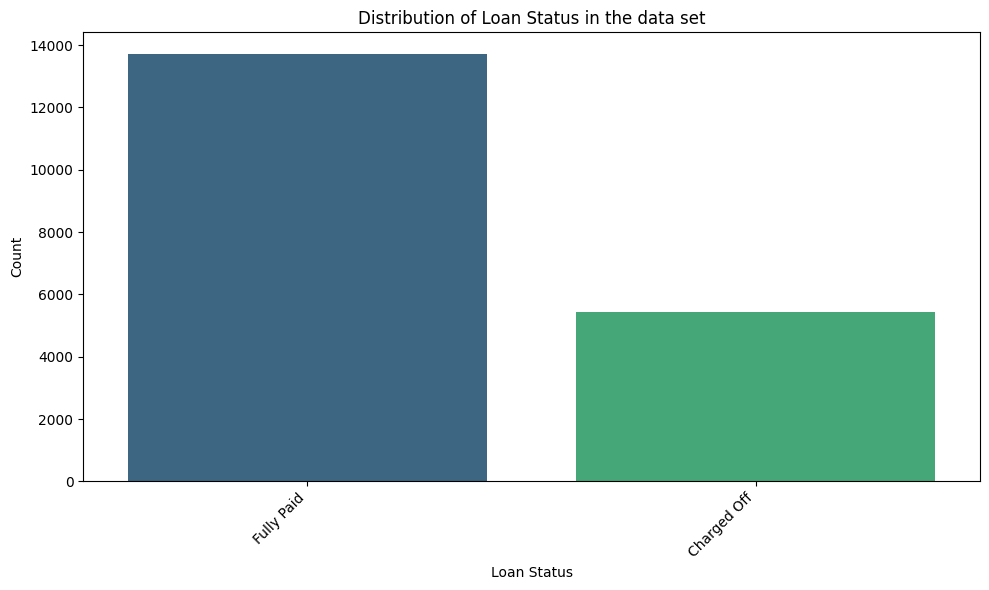

In [44]:
plt.figure(figsize=(10, 6))
sns.countplot(
    data=missing_AI_CS,
    x='Loan Status',
    palette='viridis'
)

plt.title('Distribution of Loan Status in the data set')
plt.xlabel('Loan Status')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


we create a copy of the original dataset and drop 'Loan ID', 'Customer ID', 'Purpose' as they will not be used


In [45]:
#drop loan id and customer id
#change loan term to numerical data
#make charts for categorical data and determine what type of encoding is needed for each
#NaN in deliquncy needs to be sorted
#loan_ds_copy

loan_ds_copy = loan_ds.copy()
loan_ds = loan_ds.drop(columns=['Loan ID', 'Customer ID', 'Purpose'])
loan_ds.head()

,Loan Status,Current Loan Amount,Term,Credit Score,Annual Income,Years in current job,Home Ownership,Monthly Debt,Years of Credit History,Months since last delinquent,Number of Open Accounts,Number of Credit Problems,Current Credit Balance,Maximum Open Credit,Bankruptcies,Tax Liens,nvr_delinquent
0,Fully Paid,445412.0,Short Term,709.0,1167493.0,8.0,Home Mortgage,5214.74,17.2,NaN,6.0,1.0,228190.0,416746.0,1.0,0.0,0
3,Fully Paid,347666.0,Long Term,721.0,806949.0,3.0,Own Home,8741.90,12.0,NaN,9.0,0.0,256329.0,386958.0,0.0,0.0,0
6,Fully Paid,217646.0,Short Term,730.0,1184194.0,1.0,Home Mortgage,10855.08,19.6,10.0,13.0,1.0,122170.0,272052.0,1.0,0.0,1
8,Fully Paid,548746.0,Short Term,678.0,2559110.0,2.0,Rent,18660.28,22.6,33.0,4.0,0.0,437171.0,555038.0,0.0,0.0,1
9,Fully Paid,215952.0,Short Term,739.0,1454735.0,1.0,Rent,39277.75,13.9,NaN,20.0,0.0,669560.0,1021460.0,0.0,0.0,0


In the Home Ownership column, we are faced with 4 options, "home mortgage, have mortgage, rent, own home". it is also observed that having a mortgage and home mortgage as a result, the 2 categories will be combined as one category

In [46]:
loan_ds=loan_ds[loan_ds['Home Ownership'] != 'HaveMortgage']
loan_ds['Home Ownership'].value_counts()

,count
Home Ownership,
Home Mortgage,31364
Rent,27286
Own Home,6012


In [47]:
loan_ds['Loan Status'].value_counts()

,count
Loan Status,
Fully Paid,52020
Charged Off,12642


In [48]:
loan_ds['Term'].value_counts()

,count
Term,
Short Term,45592
Long Term,19070


In [49]:
loan_ds['Months since last delinquent'].value_counts()

,count
Months since last delinquent,
13.0,604
12.0,600
14.0,593
10.0,589
18.0,584
...,...
143.0,1
91.0,1
87.0,1


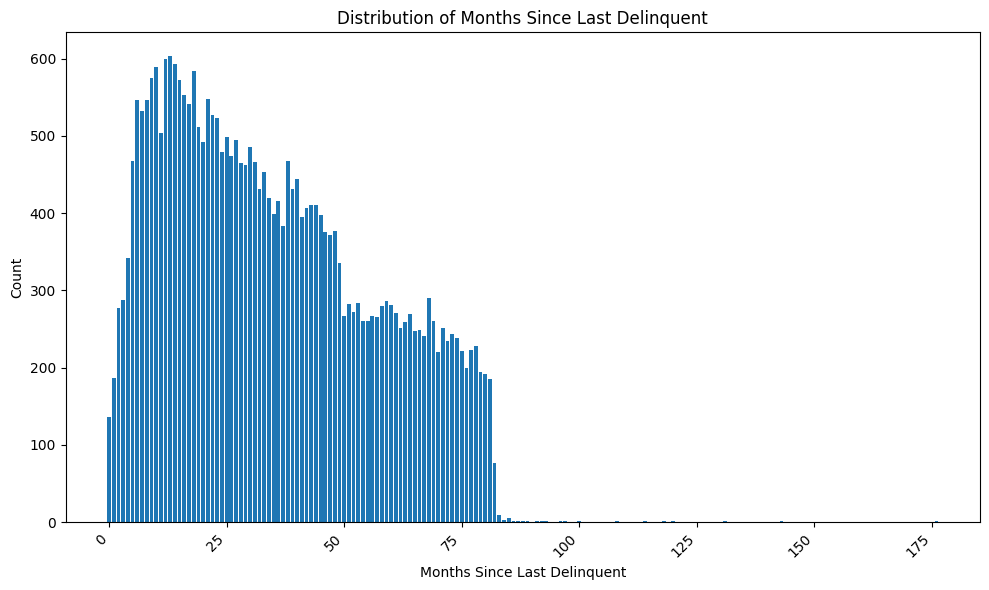

In [50]:
import matplotlib.pyplot as plt

counts = loan_ds['Months since last delinquent'].value_counts().sort_index()
plt.figure(figsize=(10, 6))
plt.bar(counts.index, counts.values)
plt.title('Distribution of Months Since Last Delinquent')
plt.xlabel('Months Since Last Delinquent')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


we will go ahead and drop the Months since last delinquent column to train the data

In [51]:
loan_ds.head()

,Loan Status,Current Loan Amount,Term,Credit Score,Annual Income,Years in current job,Home Ownership,Monthly Debt,Years of Credit History,Months since last delinquent,Number of Open Accounts,Number of Credit Problems,Current Credit Balance,Maximum Open Credit,Bankruptcies,Tax Liens,nvr_delinquent
0,Fully Paid,445412.0,Short Term,709.0,1167493.0,8.0,Home Mortgage,5214.74,17.2,NaN,6.0,1.0,228190.0,416746.0,1.0,0.0,0
3,Fully Paid,347666.0,Long Term,721.0,806949.0,3.0,Own Home,8741.90,12.0,NaN,9.0,0.0,256329.0,386958.0,0.0,0.0,0
6,Fully Paid,217646.0,Short Term,730.0,1184194.0,1.0,Home Mortgage,10855.08,19.6,10.0,13.0,1.0,122170.0,272052.0,1.0,0.0,1
8,Fully Paid,548746.0,Short Term,678.0,2559110.0,2.0,Rent,18660.28,22.6,33.0,4.0,0.0,437171.0,555038.0,0.0,0.0,1
9,Fully Paid,215952.0,Short Term,739.0,1454735.0,1.0,Rent,39277.75,13.9,NaN,20.0,0.0,669560.0,1021460.0,0.0,0.0,0


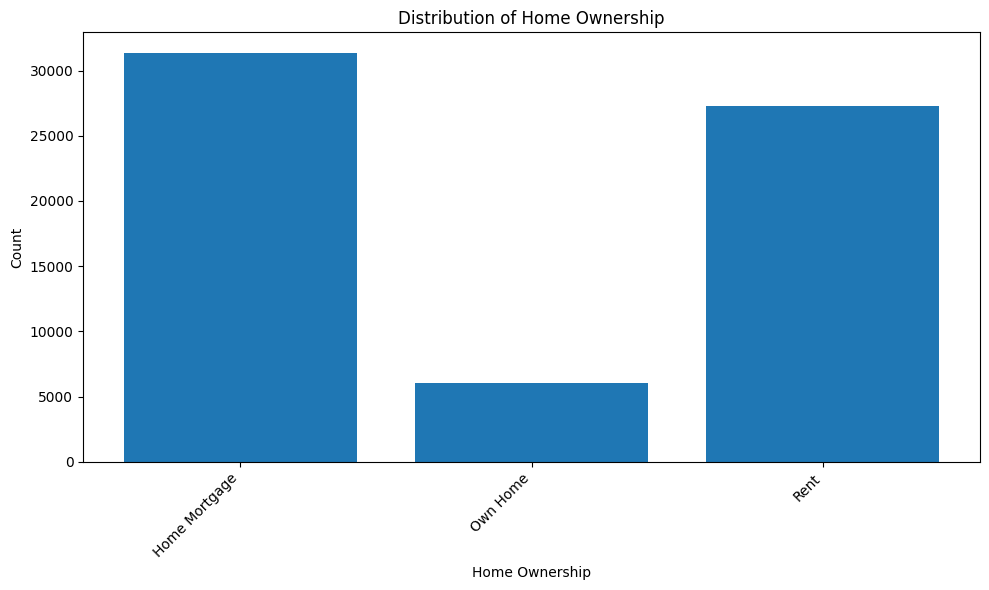

In [52]:
import matplotlib.pyplot as plt

counts = loan_ds['Home Ownership'].value_counts().sort_index()
plt.figure(figsize=(10, 6))
plt.bar(counts.index, counts.values)
plt.title('Distribution of Home Ownership')
plt.xlabel('Home Ownership')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Columns with binary categories**

*   Loan Status
*   Term

**Columns with three categories**

*   Tax Liens
*   Bankruptices
*   Home Ownership

**Total columns**: 15


In [53]:
#checking for null values
null_values = loan_ds.isnull().sum()
print("Null values in each column:")
print(null_values)

Null values in each column:
Loan Status                         0
Current Loan Amount                 0
Term                                0
Credit Score                        0
Annual Income                       0
Years in current job             2733
Home Ownership                      0
Monthly Debt                        0
Years of Credit History             0
Months since last delinquent    33771
Number of Open Accounts             0
Number of Credit Problems           0
Current Credit Balance              0
Maximum Open Credit                 0
Bankruptcies                      125
Tax Liens                           5
nvr_delinquent                      0
dtype: int64


Before the pipeline is coded, the 'Months since Delinquent' column needs to be dealt with. The column possesses many NaN values that indicate the user has never been delinquent since opening an account.

To deal with the NaN values, i will make a new column. this column will house the the NaN values and will make them 0 to show that a user has never been deliinquent ever.


In [54]:
loan_ds['nvr_delinquent'] = loan_ds['Months since last delinquent'].notna().astype(int)
loan_ds = loan_ds.drop(columns=['Months since last delinquent'])

Here we are defining what 1 and 0 are.

In [55]:
loan_ds['Loan Status'] = loan_ds['Loan Status'].map(
    {
        'Charged Off': 1,
        'Fully Paid': 0
    })
print (loan_ds['Loan Status'].value_counts())

Loan Status
0    52020
1    12642
Name: count, dtype: int64


Splitting the data into X and Y

In [56]:
X = loan_ds.drop(columns=['Loan Status'])
y = loan_ds['Loan Status']

print (f"x shape: {X.shape}")
print (f"y shape: {y.shape}")
print(f"\nFeature columns:\n{X.columns.tolist()}")

x shape: (64662, 15)
y shape: (64662,)

Feature columns:
['Current Loan Amount', 'Term', 'Credit Score', 'Annual Income', 'Years in current job', 'Home Ownership', 'Monthly Debt', 'Years of Credit History', 'Number of Open Accounts', 'Number of Credit Problems', 'Current Credit Balance', 'Maximum Open Credit', 'Bankruptcies', 'Tax Liens', 'nvr_delinquent']


In [57]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=10,
    stratify=y
)
print(f"Train size: {X_train.shape[0]} | Test size: {X_test.shape[0]}")

Train size: 51729 | Test size: 12933


We now identify the columns into 2 lists. Categorical features and numerical features.

Categorical features will be encoded and Numerical fatures will be scaled.


In [58]:
numerical_features = [
    'Current Loan Amount', 'Credit Score', 'Annual Income',
    'Years in current job', 'Monthly Debt', 'Years of Credit History',
    'Number of Open Accounts', 'Number of Credit Problems', 'Current Credit Balance',
    'Maximum Open Credit', 'Bankruptcies', 'Tax Liens',
    'nvr_delinquent'
]

categorical_features = ['Term', 'Home Ownership']

print(f"Numerical features ({len(numerical_features)}): {numerical_features}")
print(f"Categorical features ({len(categorical_features)}): {categorical_features}")

Numerical features (13): ['Current Loan Amount', 'Credit Score', 'Annual Income', 'Years in current job', 'Monthly Debt', 'Years of Credit History', 'Number of Open Accounts', 'Number of Credit Problems', 'Current Credit Balance', 'Maximum Open Credit', 'Bankruptcies', 'Tax Liens', 'nvr_delinquent']
Categorical features (2): ['Term', 'Home Ownership']


We need to start creating the pipeline that will help when creating the Logistic Regression and Support Vector Machine (SVM).
The pipeline will;

**encode - scale - algorithm**

Scaling is critical for both models, especially SVM as it is sensitive to unscaled data.

The pipelines being used are:

*   SimpleImputer (median) [Numerical pipeline]
*   SimpleImputer (most_frequent) [Categorical pipeline]
*   StandardScalar [Numerical pipeline]
*   One Hot Encoder (drop='first') [Categorical pipeline]

In [59]:
from sklearn.pipeline import Pipeline

numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler',  StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numerical_transformer, numerical_features),
    ('cat', categorical_transformer, categorical_features)
])

Next we work on the Logistic Regression pipeline. Logistic Regression is used to predict the probability of a binary outcome based on input data.

This pipeline will handle both the preprocessor and Logistic Model into one thing

In [60]:
lr_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=10,
      C=1.0
    ))
])

print("Logistic Regression pipeline created successfully")
print(lr_pipeline)

Logistic Regression pipeline created successfully
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Current Loan Amount',
                                                   'Credit Score',
                                                   'Annual Income',
                                                   'Years in current job',
                                                   'Monthly Debt',
                                                   'Years of Credit History',
                                                   'Number of Open Accounts',
        

we are now going to do the same steps for the SVM pipeline as we did for the logistic regression pipeline.

In [61]:
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline

svm_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', SVC(
        kernel='linear',
        class_weight='balanced',
        probability=True,
        random_state=42,
        C=1.0
    ))
])

print("SVM pipeline created successfully")
print(svm_pipeline)

SVM pipeline created successfully
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Current Loan Amount',
                                                   'Credit Score',
                                                   'Annual Income',
                                                   'Years in current job',
                                                   'Monthly Debt',
                                                   'Years of Credit History',
                                                   'Number of Open Accounts',
                        

We now go into .fit to trigger all functions for pipeline. This is impute, encode, scale and training; all in one call.

Only training data will be used here


In [62]:
print("Fitting Logistic Regression pipeline...")
lr_pipeline.fit(X_train, y_train)
print("Logistic Regression — Done.")

print("\nFitting SVM pipeline...")
svm_pipeline.fit(X_train, y_train)
print("SVM — Done.")

Fitting Logistic Regression pipeline...
Logistic Regression — Done.

Fitting SVM pipeline...
SVM — Done.


We now evaluate the models againt the test set.

The outcomes of the evaluation are:

*   Accuracy
*   How the model separates defaults from non-defaults (ROC-AUC)
*   how many loans were correctly and incorrectly classified



  Logistic Regression

Accuracy : 0.5688
ROC-AUC  : 0.6043

Classification Report:
              precision    recall  f1-score   support

  Fully Paid       0.85      0.56      0.68     10404
 Charged Off       0.25      0.58      0.35      2529

    accuracy                           0.57     12933
   macro avg       0.55      0.57      0.51     12933
weighted avg       0.73      0.57      0.61     12933


Confusion Matrix:


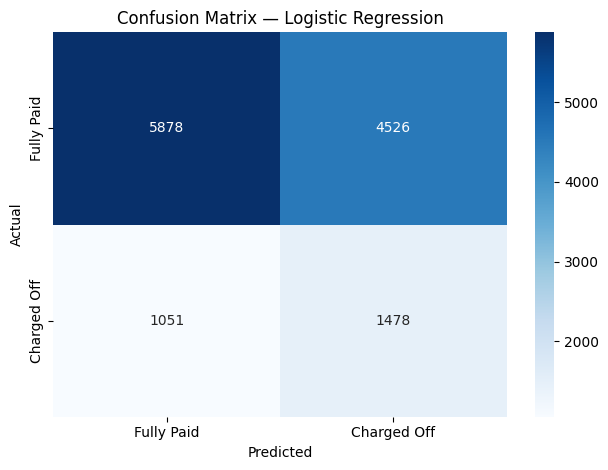


  SVM (Linear kernel)

Accuracy : 0.6562
ROC-AUC  : 0.5989

Classification Report:
              precision    recall  f1-score   support

  Fully Paid       0.82      0.73      0.77     10404
 Charged Off       0.24      0.36      0.29      2529

    accuracy                           0.66     12933
   macro avg       0.53      0.55      0.53     12933
weighted avg       0.71      0.66      0.68     12933


Confusion Matrix:


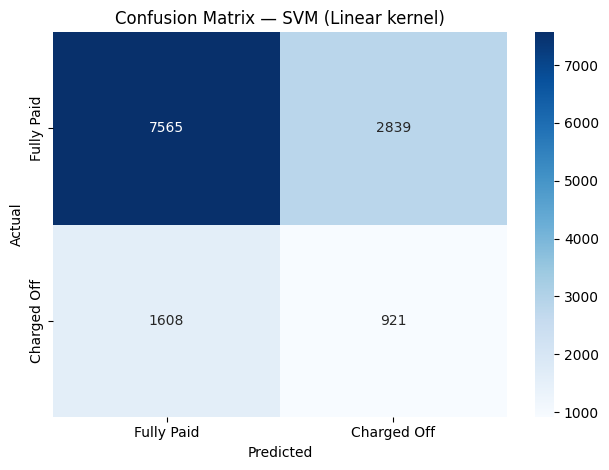

In [63]:
def evaluate_model(name, pipeline, X_test, y_test):
    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    print(f"\n{'='*55}")
    print(f"  {name}")
    print(f"{'='*55}")
    print(f"\nAccuracy : {accuracy_score(y_test, y_pred):.4f}")
    print(f"ROC-AUC  : {roc_auc_score(y_test, y_prob):.4f}")
    print(f"\nClassification Report:")
    print(classification_report(
        y_test, y_pred,
        target_names=['Fully Paid', 'Charged Off']
    ))

    print(f"\nConfusion Matrix:")
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues',
        xticklabels=['Fully Paid', 'Charged Off'],
        yticklabels=['Fully Paid', 'Charged Off']
    )
    plt.title(f'Confusion Matrix — {name}')
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.tight_layout()
    plt.show()

    return y_prob


lr_probs  = evaluate_model("Logistic Regression", lr_pipeline, X_test, y_test)
svm_probs = evaluate_model("SVM (Linear kernel)", svm_pipeline, X_test, y_test)

we now will plot the Logistic Regression model and SVM model on the same graph to compare them.

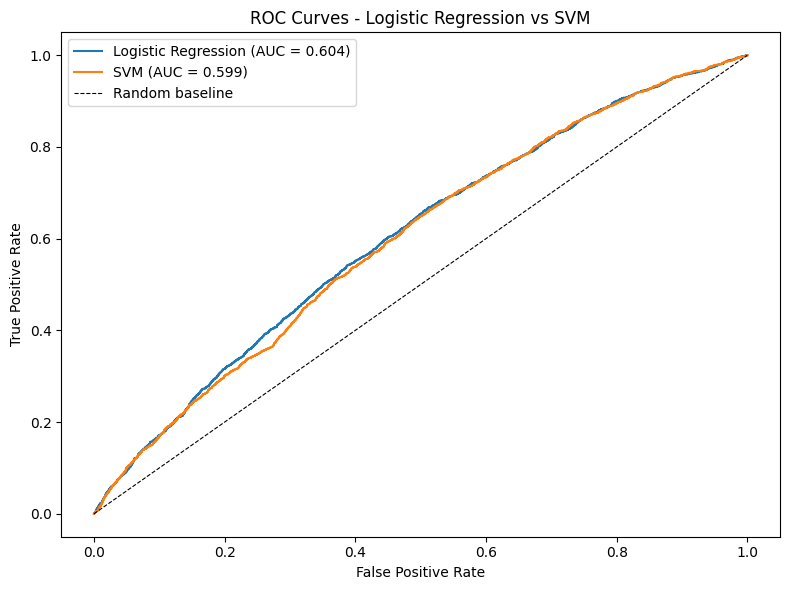

In [64]:
plt.figure(figsize=(8, 6))

for name, probs in [("Logistic Regression", lr_probs), ("SVM", svm_probs)]:
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc = roc_auc_score(y_test, probs)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0,1], [0,1], 'k--', linewidth=0.8, label='Random baseline')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - Logistic Regression vs SVM")
plt.legend()
plt.tight_layout()
plt.show()

### Model Insights and Effectiveness

After evaluating both predictive pipelines on the test data, we observe the following performance dynamics:

* **The Baseline Benchmark:** Both the Logistic Regression (AUC = 0.604) and the Support Vector Machine with a Linear Kernel (AUC = 0.599) performed similarly. Logistic Regression slightly outperformed the SVM and is the best model for this iteration.
* **The Precision-Recall Trade-off:** Using `class_weight='balanced'` in our pipelines forced both algorithms to prioritize identifying 'Charged Off' loans. As seen in the classification report, this successfully increased the recall for defaults, but resulted in a lower precision score due to false positives. In consumer finance, catching a high-risk borrower is generally prioritized over accidentally flagging a low-risk borrower.
* **Algorithm Limitations:** Because both algorithms are linear classifiers, their nearly identical AUC scores indicate that the boundary between a fully paid loan and a defaulted loan is highly non-linear. The dataset contains complex, overlapping financial patterns that cannot be perfectly separated.

Lastly, we cross validate the models

In [65]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, pipeline in [("Logistic Regression", lr_pipeline), ("SVM", svm_pipeline)]:
    scores = cross_val_score(
        pipeline, X_train, y_train,
        cv=cv,
        scoring='roc_auc',
        n_jobs=-1
    )
    print(f"\n{name}")
    print(f"  5-fold CV ROC-AUC scores : {scores.round(4)}")
    print(f"  Mean  : {scores.mean():.4f}")
    print(f"  Std   : {scores.std():.4f}")


Logistic Regression
  5-fold CV ROC-AUC scores : [0.613  0.6005 0.6189 0.6041 0.6035]
  Mean  : 0.6080
  Std   : 0.0068

SVM
  5-fold CV ROC-AUC scores : [0.6053 0.5965 0.5893 0.596  0.5988]
  Mean  : 0.5972
  Std   : 0.0052


### Conclusion

This project successfully established a data-driven baseline for credit risk analysis and loan default prediction. By cleaning the raw data and building a robust Scikit-Learn preprocessing pipeline, we achieved the following key milestones:

1. **Risk Profiling:** Exploratory Data Analysis revealed strong indicators of financial risk. Borrowers with a prior history of delinquency exhibited an elevated default rate of nearly 19%. Furthermore, a credit score falling below the dataset median of 721 served as a strong early warning indicator.
2. **Predictive Capability:** I engineered a fully automated pipeline encompassing imputation, scaling, and encoding, feeding into a Logistic Regression classifier. The model successfully established a predictive baseline that outperforms random guessing.
3. **Future Engineering Work:** To push the predictive accuracy higher, future iterations of this project will replace the linear models with non-linear, tree-based algorithms such as Random Forest or Gradient Boosting Classifiers. Additionally, we will introduce engineered features like the Debt-to-Income ratio to provide the algorithms with cleaner financial signals.

In [67]:
import joblib

# Export the trained pipeline
joblib.dump(lr_pipeline, 'loan_default_pipeline.pkl')
print("Pipeline saved successfully!")

Pipeline saved successfully!
